# Julia から Wolfram Engine を呼び出す — 方程式・不等式の厳密解を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分編・微分編の続き）。

- 方程式 `Solve` → 厳密解を表示し，**Julia の配列**として使う
- 連立方程式 → 解を **NamedTuple の配列**（`s.x`, `s.y` で取り出せる）として使う
- 不等式 `Reduce` → 解を表示し，**Julia の判定関数**（`x -> true/false`）として使う
- 領域と最大・最小 `Maximize` → 厳密な最大値と，それを与える点を使う
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Plots"])

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots

## 1. 基本：`Solve` と `Reduce`

`Solve` の結果は「置き換え規則 $x \to 値$」のリストです。`x /. Solve[...]` と書くと，解だけのリストになります。

In [3]:
weval(W`Solve[x^2 - x - 1 == 0, x]`)

W`List[List[Rule[x, Times[Rational[1, 2], Plus[1, Times[-1, Power[5, Rational[1, 2]]]]]]], List[Rule[x, Times[Rational[1, 2], Plus[1, Power[5, Rational[1, 2]]]]]]]`

In [4]:
weval(W`x /. Solve[x^2 - x - 1 == 0, x]`)

W`List[Times[Rational[1, 2], Plus[1, Times[-1, Power[5, Rational[1, 2]]]]], Times[Rational[1, 2], Plus[1, Power[5, Rational[1, 2]]]]]`

不等式は `Reduce` で解きます。結果は条件式（$\lor$ は「または」，$\land$ は「かつ」）です。

In [5]:
weval(W`Reduce[x^2 - x - 2 > 0, x, Reals]`)

W`Or[Less[x, -1], Greater[x, 2]]`

## 2. きれいに表示するための関数

In [6]:
# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = heldtex(s)

# 論理記号を日本語にする
jtex(s) = replace(s, "\\lor" => "\\ \\text{または}\\ ", "\\land" => "\\ \\text{かつ}\\ ",
                     "\\text{True}" => "\\text{すべての実数}", "\\text{False}" => "\\text{解なし}")

jtex (generic function with 1 method)

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- 不等号・等号（`Less`, `GreaterEqual`, `Inequality` など）→ Julia の比較式（`-1 < x <= 2`）
- `Or` / `And` / `Not` → `||` / `&&` / `!`
- 規則のリスト `{x -> 1, y -> 2}` → NamedTuple `(x = 1, y = 2)`

## 4. 方程式を解く → 解を Julia の配列として使う

`solve(方程式, 変数...)` にまとめます。方程式は Wolfram 言語の文字列で書きます（等号は `==`）。

- 戻り値は `(Wolfram の式, Julia の値)`。
- 変数が 1 つなら Julia の値は**解の配列**，2 つ以上なら **NamedTuple の配列**。
- `domain="Reals"` で実数解だけ，`numeric=true` で数値解（`NSolve`）。
- 厳密解が根号で簡単に表せないときは，自動的に数値にします。

In [7]:
function solve(eq::AbstractString, vars::AbstractString...; domain="", numeric=false)
    vs  = join(vars, ", ")
    dom = isempty(domain) ? "" : ", $domain"
    cmd = numeric ? "NSolve" : "Solve"
    res = weval(MathLink.parseexpr("DeleteDuplicates[Values[$cmd[$eq, {$vs}$dom]]]"))
    islist(res) || error("$cmd では解けませんでした。numeric=true や FindRoot を試してください。")
    occursin("ConditionalExpression", string(res)) &&
        error("条件つきの解です（一般解など）。方程式に範囲（例: && 0 <= x < 2 Pi）を付けてください。")
    approx = numeric || hasroot(res)
    hasroot(res) && (res = weval(W"N"(res)))

    rows = res.args                                   # 解 1 組ごとの値のリスト
    lhs  = length(vars) == 1 ? vs : "($vs)"
    one(r) = length(vars) == 1 ? tex(r.args[1]) : "\\left(" * join(tex.(r.args), ",\\ ") * "\\right)"
    rhs  = isempty(rows) ? "\\text{解なし}" : lhs * (approx ? " \\approx " : " = ") * join(one.(rows), ",\\ \\ ")
    showtex(jtex(texheld(eq)) * "\\iff " * rhs)

    if length(vars) == 1
        return res, to_value(W"List"((r.args[1] for r in rows)...))
    else
        names = Symbol.(vars)
        return res, [NamedTuple{Tuple(names)}(Tuple(to_value.(r.args))) for r in rows]
    end
end

solve (generic function with 1 method)

In [8]:
_, xs = solve("x^2 - x - 1 == 0", "x")
xs                                   # Julia の配列（Float64）

2-element Vector{Float64}:
 -0.6180339887498949
  1.618033988749895

In [9]:
_, xs = solve("6x^2 - x - 2 == 0", "x")
xs                                   # 有理数の解は Rational として厳密なまま

2-element Vector{Rational{Int64}}:
 -1//2
  2//3

In [10]:
_, xs = solve("x^2 + 2x + 5 == 0", "x")
xs                                   # 虚数解は Julia の複素数になる

2-element Vector{Complex{Int64}}:
 -1 - 2im
 -1 + 2im

In [11]:
solve("x^2 + 2x + 5 == 0", "x"; domain="Reals")[2]      # 実数の範囲では解なし → 空の配列

Any[]

**検算とグラフ**：解を元の式に代入し，グラフ上に点を打ちます。

In [12]:
pstr = "x^4 - 5x^2 + 2x + 3"
p = wfun(pstr, :x)
_, xs = solve("$pstr == 0", "x")

@show xs
@show p.(xs);                        # ほぼ 0

xs = [-0.6180339887498949, 1.618033988749895, -2.302775637731995, 1.3027756377319946]
p.(xs) = [-2.220446049250313e-16, 8.881784197001252e-16, 0.0, -8.881784197001252e-16]


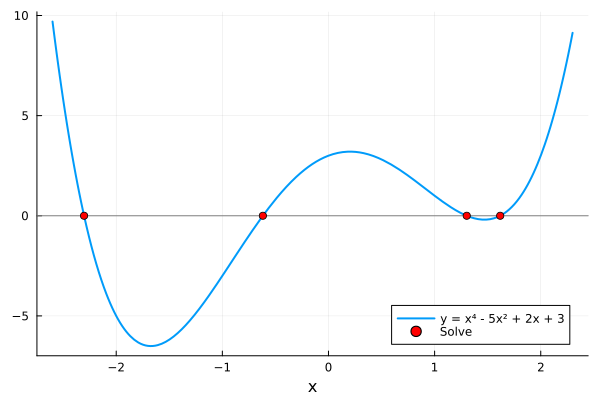

In [13]:
plot(p, -2.6, 2.3; label="y = x⁴ - 5x² + 2x + 3", lw=2, xlabel="x")
hline!([0]; color=:gray, label="")
scatter!(xs, zero(xs); label="Solve", color=:red)

### いろいろな方程式

指数・対数・無理方程式，範囲つきの三角方程式もそのまま解けます。

In [14]:
solve("4^x - 3 2^x - 4 == 0", "x"; domain="Reals")
solve("Log[2, x] + Log[2, x - 2] == 3", "x")
solve("Sqrt[x + 2] == x", "x")
solve("Sin[x] == 1/2 && 0 <= x < 2 Pi", "x")
_, θs = solve("2 Cos[x]^2 + Sin[x] - 1 == 0 && 0 <= x < 2 Pi", "x")
θs

3-element Vector{Float64}:
 1.5707963267948966
 3.6651914291880923
 5.759586531581287

### 厳密解が簡単に書けないとき・解けないとき

- 3 次方程式 $x^3-3x+1=0$ は実数解を 3 つ持ちますが，根号で書くと虚数が現れます（還元不能の場合）。`solve` は自動的に数値にします。
- 5 次以上は一般に根号で解けません。`numeric=true` で数値解を求めます。
- $\cos x = x$ のような超越方程式は `FindRoot`（初期値が必要）を使います。

In [15]:
_, r3 = solve("x^3 - 3x + 1 == 0", "x")
r3

3-element Vector{Float64}:
 -1.8793852415718169
  0.34729635533386066
  1.532088886237956

In [16]:
_, r5 = solve("x^5 - x - 1 == 0", "x"; numeric=true)                    # 複素数解も含めて 5 個
_, r5real = solve("x^5 - x - 1 == 0", "x"; domain="Reals", numeric=true)
r5real

1-element Vector{Float64}:
 1.1673039782614187

In [17]:
fr = to_value(weval(W`FindRoot[Cos[x] == x, {x, 1}]`))     # 規則のリスト → NamedTuple
@show fr
@show cos(fr.x) - fr.x;

fr = (x = 0.7390851332151607,)
cos(fr.x) - fr.x = 0.0


## 5. 連立方程式 → NamedTuple の配列

変数を複数渡すと，解 1 組が `(x = ..., y = ...)` になります。

In [18]:
_, s = solve("{2x + 3y == 7, 4x - y == 5}", "x", "y")
s[1].x, s[1].y                       # 有理数は厳密

(11//7, 9//7)

In [19]:
_, s = solve("{x + y == 5, x y == 6}", "x", "y")
s

2-element Vector{@NamedTuple{x::Int64, y::Int64}}:
 (x = 2, y = 3)
 (x = 3, y = 2)

**放物線と直線の交点**：厳密な座標を求めて，グラフに描きます。

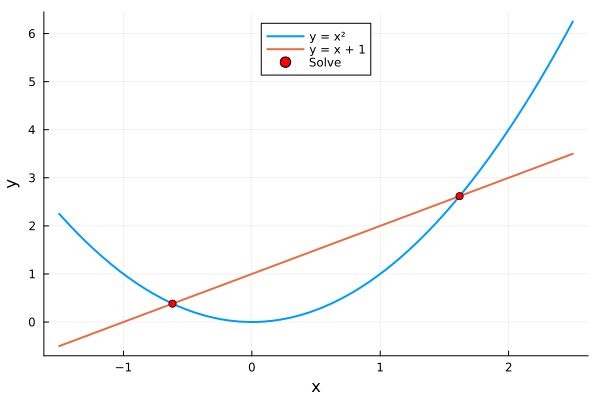

In [20]:
_, pts = solve("{y == x^2, y == x + 1}", "x", "y")

plot(x -> x^2, -1.5, 2.5; label="y = x²", lw=2, xlabel="x", ylabel="y")
plot!(x -> x + 1, -1.5, 2.5; label="y = x + 1", lw=2)
scatter!([q.x for q in pts], [q.y for q in pts]; label="Solve", color=:red, legend=:top)

**円と直線の交点**

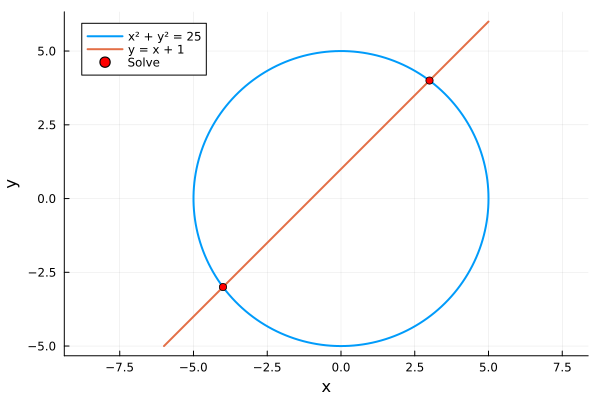

In [21]:
_, pts = solve("{x^2 + y^2 == 25, y == x + 1}", "x", "y")

θ = range(0, 2π; length=200)
plot(5cos.(θ), 5sin.(θ); label="x² + y² = 25", lw=2, aspect_ratio=1, xlabel="x", ylabel="y")
plot!(x -> x + 1, -6, 5; label="y = x + 1", lw=2)
scatter!([q.x for q in pts], [q.y for q in pts]; label="Solve", color=:red, legend=:topleft)

## 6. 文字を含む方程式 → 解の公式を Julia の関数にする

係数を文字のまま解くと，解は係数の式になります。これを Julia の関数にすれば「解の公式」です。

In [22]:
qw = weval(W`x /. Solve[a x^2 + b x + c == 0, x]`)
showtex("a x^2 + b x + c = 0 \\iff x = " * join(tex.(qw.args), ",\\ \\ "))

quadratic = to_function(qw, :a, :b, :c)      # (a, b, c) -> 2 つの解のベクトル
to_expr(qw)

:([1 // 2 * pw(a, -1) * (-b + -(sqrt(b ^ 2 + -4 * a * c))), 1 // 2 * pw(a, -1) * (-b + sqrt(b ^ 2 + -4 * a * c))])

In [23]:
@show quadratic(1, -1, -1)                   # x² - x - 1 = 0
@show quadratic(6, -1, -2)                   # 6x² - x - 2 = 0
@show quadratic(1, 2, complex(5));           # 判別式が負のときは複素数で渡す（sqrt(負の実数) はエラーになるため）

quadratic(1, -1, -1) = [-0.6180339887498949, 1.618033988749895]
quadratic(6, -1, -2) = [-0.5, 0.6666666666666666]
quadratic(1, 2, complex(5)) = ComplexF64[-1.0 - 2.0im, -1.0 + 2.0im]


## 7. 不等式を解く → 解を判定関数として使う

`Reduce` の結果（条件式）を，「$x$ が解に含まれるか」を返す Julia の関数に変換します。  
戻り値は `(Wolfram の式, Julia の判定関数)` です。

In [24]:
function solve_ineq(ineq::AbstractString, var::AbstractString="x"; domain="Reals")
    res = weval(MathLink.parseexpr("Reduce[$ineq, $var, $domain]"))
    approx = hasroot(res)
    approx && (res = weval(W"N"(res)))
    showtex(jtex(texheld(ineq)) * "\\iff " * jtex(tex(res)) * (approx ? "\\quad(\\text{数値})" : ""))
    return res, to_function(res, Symbol(var))
end

solve_ineq (generic function with 2 methods)

In [25]:
sw, inS = solve_ineq("x^2 - x - 2 > 0")
to_expr(sw)                          # Julia の条件式に変換されたもの

:(x < -1 || x > 2)

In [26]:
inS(-2), inS(0), inS(2), inS(2.5)    # x が解に含まれるか

(true, false, false, true)

In [27]:
filter(inS, -4:4)                    # 解に含まれる整数だけ取り出す

5-element Vector{Int64}:
 -4
 -3
 -2
  3
  4

**グラフで確認**：解の範囲を $x$ 軸上に太線で描きます。

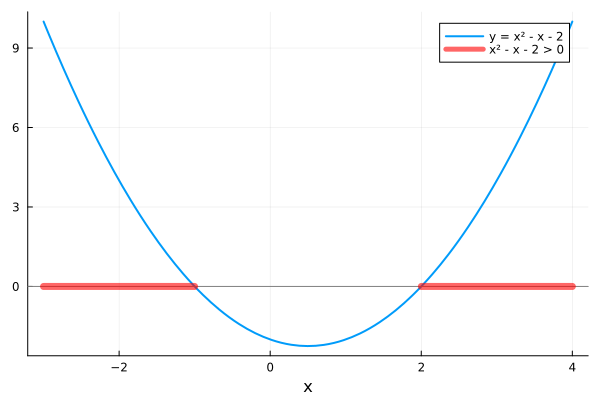

In [28]:
# 判定関数 inS が true になる範囲を x 軸上に太線で描く
function plot_solution!(inS, a, b; n=2001, kw...)
    xs = range(a, b; length=n)
    plot!(xs, [inS(x) ? 0.0 : NaN for x in xs]; lw=7, alpha=0.6, kw...)
end

plot(x -> x^2 - x - 2, -3, 4; label="y = x² - x - 2", lw=2, xlabel="x")
hline!([0]; color=:gray, label="")
plot_solution!(inS, -3, 4; color=:red, label="x² - x - 2 > 0")

### いろいろな不等式

In [29]:
solve_ineq("x^2 - x - 2 <= 0")
solve_ineq("(x - 1)/(x + 2) >= 0")
solve_ineq("Abs[x - 1] + Abs[x + 2] < 5")
solve_ineq("{x^2 - 4 < 0, x^2 - x > 0}")          # 連立不等式
solve_ineq("x^2 + 1 > 0")
solve_ineq("x^2 + 1 < 0")
solve_ineq("x^3 - 3x + 1 > 0");                   # 境界が根号で簡単に書けない → 数値

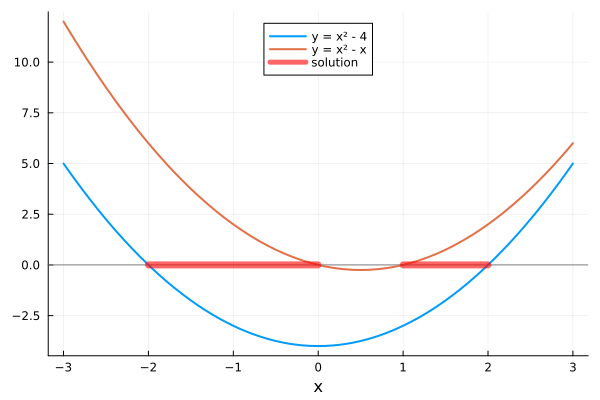

In [30]:
_, inT = solve_ineq("{x^2 - 4 < 0, x^2 - x > 0}")

plot(x -> x^2 - 4, -3, 3; label="y = x² - 4", lw=2, xlabel="x")
plot!(x -> x^2 - x, -3, 3; label="y = x² - x", lw=2)
hline!([0]; color=:gray, label="")
plot_solution!(inT, -3, 3; color=:red, label="solution", legend=:top)

### 文字を含む不等式・解の存在条件

- 文字 $a$ を含む不等式は，$a$ による場合分けつきで解かれます。$(a, x)$ の判定関数にできます。
- `Exists`（ある $x$ が存在する），`ForAll`（すべての $x$ で成り立つ）で，$a$ の条件を求められます。

In [31]:
cw = weval(W`Reduce[x^2 - 2 a x + a + 2 > 0, x, Reals]`)
showtex("x^2 - 2ax + a + 2 > 0 \\iff " * jtex(tex(cw)))

inA = to_function(cw, :a, :x)        # (a, x) -> true/false
inA(0, 1), inA(3, 1), inA(3, 6)

(true, false, true)

In [32]:
ew = weval(W`Reduce[Exists[x, x^2 + a x + 1 == 0], a, Reals]`)
fw = weval(W`Reduce[ForAll[x, x^2 + a x + 1 > 0], a, Reals]`)
showtex("x^2 + ax + 1 = 0 \\text{ が実数解をもつ} \\iff " * jtex(tex(ew)))
showtex("\\text{すべての実数 } x \\text{ で } x^2 + ax + 1 > 0 \\iff " * jtex(tex(fw)))

hasreal = to_function(ew, :a)
all(hasreal(a) == (a^2 - 4 >= 0) for a in -3:0.25:3)      # 判別式 D = a² - 4 ≥ 0 による判定と一致するか

true

## 8. 領域と最大・最小

2 変数の不等式は，そのまま $(x, y)$ の判定関数にして領域を図示できます。  
`Maximize[{目的関数, 条件}, {x, y}]` は `{最大値, {x -> .., y -> ..}}` を厳密に返します。

In [33]:
cond = "x >= 0 && y >= 0 && x + y <= 4 && x + 3y <= 6"
inD  = wfun(cond, :x, :y)                          # (x, y) -> 領域に含まれるか

mw = weval(MathLink.parseexpr("Maximize[{x + 2y, $cond}, {x, y}]"))
showtex(jtex(texheld(cond)) * "\\text{ のとき }\\ \\max(x + 2y) = " * tex(mw.args[1]) *
        "\\quad \\left(" * tex(mw.args[2]) * "\\right)")

kmax, pt = to_value(mw)                            # 最大値と，それを与える点 (x = .., y = ..)

2-element Vector{Any}:
 5
  (x = 3, y = 1)

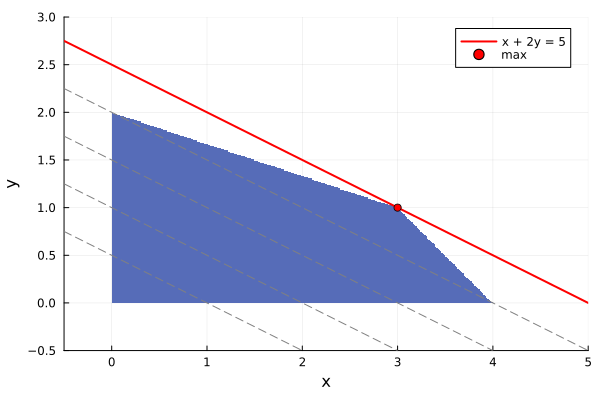

In [34]:
gx = range(-0.5, 5; length=400); gy = range(-0.5, 3; length=300)
heatmap(gx, gy, (x, y) -> inD(x, y) ? 1.0 : NaN; color=:blues, colorbar=false, clims=(0, 2),
        xlabel="x", ylabel="y", aspect_ratio=1, xlims=(-0.5, 5), ylims=(-0.5, 3))
for k in 1:kmax
    plot!(x -> (k - x) / 2, -0.5, 5; color=:gray, ls=:dash, label="")       # x + 2y = k
end
plot!(x -> (kmax - x) / 2, -0.5, 5; color=:red, lw=2, label="x + 2y = $kmax")
scatter!([pt.x], [pt.y]; color=:red, label="max")

曲線で囲まれた領域でも同じです。最大値が $2\sqrt2$ のような無理数でも厳密に求まります。

In [35]:
cond2 = "x^2 + y^2 <= 4 && y >= x^2 - 1"
inD2  = wfun(cond2, :x, :y)

mw2 = weval(MathLink.parseexpr("Maximize[{x + y, $cond2}, {x, y}]"))
showtex(jtex(texheld(cond2)) * "\\text{ のとき }\\ \\max(x + y) = " * tex(mw2.args[1]) *
        "\\quad \\left(" * tex(mw2.args[2]) * "\\right)")

kmax2, pt2 = to_value(mw2)

2-element Vector{Any}:
 2.8284271247461903
  (x = 1.4142135623730951, y = 1.4142135623730951)

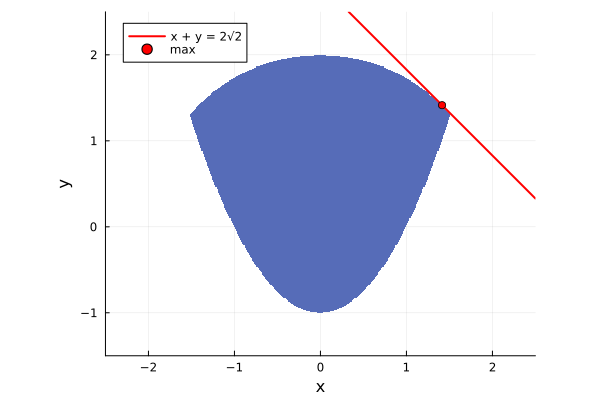

In [36]:
gx = range(-2.5, 2.5; length=400); gy = range(-1.5, 2.5; length=320)
heatmap(gx, gy, (x, y) -> inD2(x, y) ? 1.0 : NaN; color=:blues, colorbar=false, clims=(0, 2),
        xlabel="x", ylabel="y", aspect_ratio=1, xlims=(-2.5, 2.5), ylims=(-1.5, 2.5))
plot!(x -> kmax2 - x, -0.5, 2.5; color=:red, lw=2, label="x + y = 2√2")
scatter!([pt2.x], [pt2.y]; color=:red, label="max")

## 9. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **`Solve` が解けない**：`solve(...; numeric=true)`（多項式など）や `FindRoot`（初期値つき）を使います。
- **三角方程式で「条件つきの解」エラー**：一般解（整数 $n$ を含む解）は Julia の値にできません。`&& 0 <= x < 2 Pi` のように範囲を付けます。
- **等号は `==`**：`=` は Wolfram 言語では代入です。
- **未対応の関数が出た**：エラーメッセージに出た名前を `WFUNC` に追加します。

In [37]:
# 範囲を付けない三角方程式：一般解（整数 n を含む）になるので，Julia の値にはできない
try
    solve("Sin[x] == 1/2", "x")
catch e
    println(e.msg)
end

条件つきの解です（一般解など）。方程式に範囲（例: && 0 <= x < 2 Pi）を付けてください。


In [38]:
# 超越方程式：Solve では解けない
try
    solve("Cos[x] == x", "x")
catch e
    println(e.msg)
end

┌ Warning: Solve::nsmet: This system cannot be solved with the methods available to
│     Solve. Try Reduce or FindInstance instead.
└ @ MathLink ~/.julia/packages/MathLink/WEvUg/src/eval.jl:16
┌ Warning: Values::invrl: The argument Solve[Cos[x] == x, {x}]
│      is not a valid Association or a list of rules.
└ @ MathLink ~/.julia/packages/MathLink/WEvUg/src/eval.jl:16


Solve では解けませんでした。numeric=true や FindRoot を試してください。
